<a href="https://colab.research.google.com/github/emilianomtz0189/credit-risk-scorecard/blob/main/notebooks/04_scorecard.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 04 · Regresión logística y scorecard de puntos

**Objetivo:** estimar la PD de cada cliente con una regresión logística sobre las variables WoE y convertir el modelo en un **scorecard**: una tabla de puntos fácil de leer, aplicar y explicar.

## Conceptos

### 1. Regresión logística

Estima la probabilidad de ser malo (la **PD**) a partir de las variables:

$$\text{PD} = \frac{1}{1 + e^{-(\beta_0 + \beta_1 \cdot \text{WoE}_1 + \dots + \beta_k \cdot \text{WoE}_k)}}$$

- Cada **coeficiente** (β) dice cuánto pesa la variable en el riesgo.
- Como el WoE es **positivo en los tramos de menor riesgo**, todos los coeficientes deben salir **negativos**: a mayor WoE, menor PD. Un coeficiente positivo contradice la lógica del WoE y suele indicar que dos variables se están "peleando" la misma información (multicolinealidad); esa variable se elimina.
- El **p-valor** dice si el efecto de la variable es real o podría ser casualidad. Se exige un p-valor menor a 0.05.

Es el modelo estándar para scorecards porque es **transparente**: se puede explicar a la dirección, a auditoría y al regulador exactamente por qué un cliente recibió su calificación.

### 2. De probabilidades a puntos

Los **momios** (*odds*) son buenos por cada malo. Una PD de 2 % equivale a momios de 49 a 1. El scorecard traduce los momios a puntos con dos parámetros:

| Parámetro | Valor | Significado |
|---|---|---|
| Puntaje base | 600 | Un cliente con 600 puntos tiene momios de 50 buenos por cada malo. |
| PDO (*Points to Double the Odds*) | 20 | Cada 20 puntos adicionales, los momios se duplican: 620 puntos = 100 a 1; 580 puntos = 25 a 1. |

Así, **más puntos = menos riesgo**, igual que el score de Buró. Los puntos de cada tramo se calculan para que, al sumarlos, den exactamente el puntaje que corresponde a la PD del modelo.

## Entorno

In [1]:
import os
import sys
from pathlib import Path

USUARIO_GITHUB = "emilianomtz0189"
NOMBRE_REPO = "credit-risk-scorecard"
CARPETA_DRIVE = Path("/content/drive/MyDrive/credit-risk-scorecard")  # Donde está cs-training.csv

EN_COLAB = "google.colab" in sys.modules

if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

    ruta_repo = Path("/content") / NOMBRE_REPO
    if not ruta_repo.exists():
        !git clone -q https://github.com/{USUARIO_GITHUB}/{NOMBRE_REPO}.git {ruta_repo}
    else:
        !git -C {ruta_repo} pull -q
    os.chdir(ruta_repo)
elif Path.cwd().name == "notebooks":
    os.chdir("..")

sys.path.insert(0, str(Path.cwd()))
print("Directorio de trabajo:", Path.cwd())

Mounted at /content/drive
Directorio de trabajo: /content/credit-risk-scorecard


In [2]:
!pip install -q -r requirements.txt

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src import config
from src.datos import copiar_datos_crudos
from src.limpieza import obtener_datos_limpios
from src.scorecard import (
    FACTOR,
    MOMIOS_BASE,
    OFFSET,
    PDO,
    PUNTAJE_BASE,
    ajustar_logistica,
    desglose_cliente,
    graficar_distribucion_puntajes,
    pd_desde_puntaje,
    puntaje_clientes,
    tabla_calibracion,
    tabla_puntos,
)
from src.woe import preparar_woe

config.fijar_semilla()
config.crear_carpetas()
pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.max_rows", 100)

In [4]:
# Datos limpios y transformación WoE de las etapas 2 y 3 (se regeneran en una sesión nueva)
copiar_datos_crudos(CARPETA_DRIVE)
train, test = obtener_datos_limpios()
agrupador, seleccion, train_woe, test_woe = preparar_woe()

Y = config.COLUMNA_OBJETIVO
print(f"Variables candidatas de la etapa 3 ({len(seleccion)}):", seleccion)

Copiado cs-training.csv a data/raw/cs-training.csv
Variables candidatas de la etapa 3 (10): ['uso_credito_revolvente', 'atrasos_90', 'atrasos_30_59', 'atrasos_60_89', 'edad', 'num_creditos_abiertos', 'razon_deuda', 'ingreso_mensual', 'num_creditos_inmobiliarios', 'num_dependientes']


## 1. Regresión logística

Se ajusta con la muestra de entrenamiento. Si alguna variable sale con signo positivo o con p-valor mayor a 0.05, se elimina y se vuelve a ajustar, de una en una.

In [5]:
modelo, variables, eliminadas = ajustar_logistica(train_woe, seleccion)

print(f"Variables en el modelo final ({len(variables)}):", variables)
print("\nVariables eliminadas:")
display(eliminadas if not eliminadas.empty else "Ninguna")

Variables en el modelo final (8): ['uso_credito_revolvente', 'atrasos_90', 'atrasos_30_59', 'atrasos_60_89', 'edad', 'razon_deuda', 'num_creditos_inmobiliarios', 'num_dependientes']

Variables eliminadas:


,variable,motivo
0,num_creditos_abiertos,p-valor 0.712
1,ingreso_mensual,p-valor 0.629


In [6]:
# Coeficientes del modelo final
modelo.tabla_coeficientes()

,coeficiente,error_estandar,z,p_valor
intercepto,-2.6065,0.0151,-172.9334,0.0000
uso_credito_revolvente,-0.6120,0.0140,-43.5870,0.0000
atrasos_90,-0.5383,0.0137,-39.3975,0.0000
atrasos_30_59,-0.4790,0.0157,-30.4300,0.0000
atrasos_60_89,-0.3859,0.0171,-22.5456,0.0000
edad,-0.4104,0.0324,-12.6761,0.0000
razon_deuda,-0.8944,0.0497,-17.9811,0.0000
num_creditos_inmobiliarios,-0.7045,0.0588,-11.9810,0.0000
num_dependientes,-0.2364,0.0763,-3.1004,0.0019


**Cómo leer la tabla:**
- `coeficiente`: todos los de las variables deben ser negativos.
- `error_estandar` y `z`: precisión del coeficiente; z = coeficiente ÷ error estándar.
- `p_valor`: probabilidad de ver un efecto así por casualidad. Menor a 0.05 = efecto real.
- El **intercepto** refleja el riesgo base de la cartera.

## 2. Scorecard: puntos por tramo

In [7]:
print(f"Escala: {PUNTAJE_BASE} puntos = momios de {MOMIOS_BASE} a 1 | PDO = {PDO}")
print(f"factor = PDO / ln(2) = {FACTOR:.4f}")
print(f"offset = {PUNTAJE_BASE} - factor × ln({MOMIOS_BASE}) = {OFFSET:.4f}")

puntos = tabla_puntos(modelo, agrupador)
puntos

Escala: 600 puntos = momios de 50 a 1 | PDO = 20
factor = PDO / ln(2) = 28.8539
offset = 600 - factor × ln(50) = 487.1229


clientes  tasa_malos     woe  puntos
variable                   tramo                                            
uso_credito_revolvente     ≤ 0.27          62899      0.0215  1.1819      91
                           0.27 – 0.35      5241      0.0462  0.3917      77
                           0.35 – 0.44      5242      0.0582  0.1479      73
                           0.44 – 0.56      5241      0.0765 -0.1456      68
                           0.56 – 0.69      5242      0.1011 -0.4513      62
                           0.69 – 0.85      5241      0.1421 -0.8387      55
                           0.85 – 1.00     13563      0.1903 -1.1882      49
                           > 1.00           2162      0.3913 -2.1945      32
                           Faltante          169      0.0947 -0.3785      64
atrasos_90                 0               99103      0.0460  0.3959      76
                           1+               5715      0.4131 -2.2852      35
                           Faltante          182      0.5440 -2.8126      27
atrasos_30_59              0               88178      0.0404  0.5321      78
                           1               11252      0.1475 -0.8822      58
                           2                3225      0.2685 -1.6342      48
                           3+               2163      0.3851 -2.1684      40
                           Faltante          182      0.5440 -2.8126      31
atrasos_60_89              0               99662      0.0509  0.2895      74
                           1+               5156      0.3582 -2.0532      47
                           Faltante          182      0.5440 -2.8126      39
edad                       ≤ 33            11943      0.1114 -0.5594      64
                           34–36            4728      0.0996 -0.4348      65
                           37–41           10083      0.0909 -0.3342      66
                           42–52           27407      0.0799 -0.1922      68
                           53–54            5053      0.0695 -0.0413      70
                           55–58            9732      0.0582  0.1484      72
                           59–63           12176      0.0467  0.3792      75
                           64+             23878      0.0262  0.9801      82
                           Faltante            0         NaN  0.0000      70
razon_deuda                ≤ 0.02           8315      0.0515  0.2775      77
                           0.02 – 0.36     41564      0.0597  0.1211      73
                           0.36 – 0.43      8313      0.0652  0.0266      71
                           0.43 – 0.47      4156      0.0698 -0.0462      69
                           0.47 – 0.53      4157      0.0772 -0.1556      66
                           0.53 – 0.61      4156      0.0926 -0.3545      61
                           0.61 – 0.72      4158      0.0964 -0.3989      60
                           > 0.72           8312      0.1190 -0.6342      54
                           Faltante        21869      0.0540  0.2260      76
num_creditos_inmobiliarios 0               39193      0.0831 -0.2347      66
                           1               36731      0.0522  0.2619      76
                           2               22106      0.0561  0.1867      74
                           3                4426      0.0712 -0.0675      69
                           4+               2544      0.1136 -0.5818      58
                           Faltante            0         NaN  0.0000      70
num_dependientes           0               60782      0.0589  0.1349      71
                           1               18498      0.0738 -0.1072      70
                           2               13644      0.0808 -0.2043      69
                           3                6647      0.0891 -0.3112      68
                           4+               2708      0.0979 -0.4151      67
                           Faltante         2721      0.0415  0.5026      74

**Cómo leer el scorecard:** para calificar a un cliente se busca en qué tramo cae en cada variable y se suman los puntos. Los tramos de menor riesgo dan más puntos. El tramo "Faltante" de una variable sin faltantes en entrenamiento recibe los puntos de riesgo promedio (WoE = 0).

In [8]:
# Rango de puntos por variable: cuánto puede mover cada variable el puntaje total
rango_puntos = (puntos.groupby(level="variable")["puntos"]
                .agg(minimo="min", maximo="max")
                .assign(rango=lambda t: t["maximo"] - t["minimo"])
                .sort_values("rango", ascending=False))
rango_puntos

,minimo,maximo,rango
variable,,,
uso_credito_revolvente,32,91,59
atrasos_90,27,76,49
atrasos_30_59,31,78,47
atrasos_60_89,39,74,35
razon_deuda,54,77,23
edad,64,82,18
num_creditos_inmobiliarios,58,76,18
num_dependientes,67,74,7


## 3. Puntaje de cada cliente

In [9]:
puntaje_train = puntaje_clientes(train, agrupador, puntos)
puntaje_test = puntaje_clientes(test, agrupador, puntos)   # Mismo scorecard, clientes nuevos

pd.DataFrame({
    "entrenamiento": puntaje_train["puntaje"].describe(),
    "prueba": puntaje_test["puntaje"].describe(),
})

,entrenamiento,prueba
count,"105,000.0000","45,000.0000"
mean,582.6924,582.8551
std,33.8998,33.6766
min,402.0000,414.0000
25%,565.0000,565.0000
50%,593.0000,593.0000
75%,607.0000,607.0000
max,627.0000,627.0000


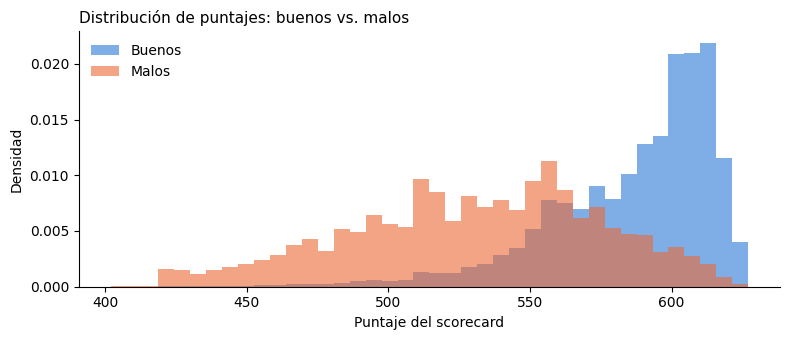

In [10]:
graficar_distribucion_puntajes(puntaje_train["puntaje"], train[Y])
plt.show()

Si el scorecard funciona, los **malos se concentran en puntajes bajos** y los **buenos en puntajes altos**. Cuanto menos se traslapen las dos distribuciones, mejor separa el modelo. En la etapa 6 esto se mide formalmente con AUC, Gini y KS.

## 4. Calibración: ¿la PD del scorecard coincide con la realidad?

Se divide a los clientes en 10 grupos por puntaje y se compara la **PD que dice el scorecard** con la **tasa de malos real** de cada grupo. Que coincidan importa porque la PD se usará en la etapa 7 para calcular la pérdida esperada.

In [11]:
print("Entrenamiento")
display(tabla_calibracion(puntaje_train["puntaje"], train[Y]))
print("Prueba")
display(tabla_calibracion(puntaje_test["puntaje"], test[Y]))

Entrenamiento


,clientes,malos,tasa_malos_real,pd_promedio
rango_puntaje,,,,
402–538,10604,3798,0.3582,0.3494
538–558,10591,1206,0.1139,0.1012
558–572,11036,769,0.0697,0.0620
572–583,10141,451,0.0445,0.0412
583–593,10973,297,0.0271,0.0285
593–600,10891,172,0.0158,0.0217
600–605,10749,116,0.0108,0.0177
605–610,9297,84,0.0090,0.0150
610–615,12109,82,0.0068,0.0125


Prueba


,clientes,malos,tasa_malos_real,pd_promedio
rango_puntaje,,,,
414–539,4556,1651,0.3624,0.3442
539–559,4768,528,0.1107,0.0981
559–572,4425,275,0.0621,0.0608
572–583,4294,168,0.0391,0.0413
583–593,4878,160,0.0328,0.0285
593–600,4658,76,0.0163,0.0217
600–605,4520,53,0.0117,0.0177
605–610,4002,45,0.0112,0.0150
610–615,5295,29,0.0055,0.0124


## 5. Ejemplo: explicar la calificación de un cliente

En crédito no basta con decir "rechazado": hay que poder explicar por qué. El desglose muestra los puntos de cada variable; las de menos puntos son las **razones principales** de un puntaje bajo (*reason codes*). Se toman de la muestra de prueba el cliente con el puntaje más bajo y el de puntaje más alto.

In [12]:
for etiqueta, id_cliente in [("más bajo", puntaje_test["puntaje"].idxmin()),
                             ("más alto", puntaje_test["puntaje"].idxmax())]:
    total = puntaje_test.loc[id_cliente, "puntaje"]
    print(f"\nCliente {id_cliente} (puntaje {etiqueta}): {total} puntos | "
          f"PD = {pd_desde_puntaje(total):.2%} | ¿Fue malo? {'Sí' if test.loc[id_cliente, Y] else 'No'}")
    display(desglose_cliente(id_cliente, test, agrupador, puntos).sort_values("puntos"))


Cliente 107427 (puntaje más bajo): 414 puntos | PD = 92.65% | ¿Fue malo? No


,valor,tramo,puntos
variable,,,
uso_credito_revolvente,1.0352,> 1.00,32
atrasos_90,3.0000,1+,35
atrasos_30_59,3.0000,3+,40
atrasos_60_89,1.0000,1+,47
razon_deuda,0.6513,0.61 – 0.72,60
edad,40.0000,37–41,66
num_creditos_inmobiliarios,0.0000,0,66
num_dependientes,3.0000,3,68



Cliente 264 (puntaje más alto): 627 puntos | PD = 0.78% | ¿Fue malo? No


,valor,tramo,puntos
variable,,,
atrasos_60_89,0.0000,0,74
num_dependientes,NaN,Faltante,74
razon_deuda,NaN,Faltante,76
atrasos_90,0.0000,0,76
num_creditos_inmobiliarios,1.0000,1,76
atrasos_30_59,0.0000,0,78
edad,78.0000,64+,82
uso_credito_revolvente,0.0247,≤ 0.27,91


## Hallazgos de la etapa

- **Modelo final con 8 variables.** Se eliminaron `num_creditos_abiertos` (p-valor 0.712) e `ingreso_mensual` (p-valor 0.629). Por sí solas tenían un IV débil, pero junto con las demás no aportan información nueva: lo que dicen ya lo explican el uso de crédito, la razón de deuda y los atrasos.
- **Coeficientes:** todos negativos y con p-valor menor a 0.05, como exige la lógica del WoE.
- **Peso de cada variable (rango de puntos):** uso de crédito 59, atrasos de 90+ días 49, atrasos de 30–59 días 47, atrasos de 60–89 días 35, razón de deuda 23, edad 18, créditos inmobiliarios 18 y dependientes 7.
- **Puntajes:** de 402 a 627 en entrenamiento, con mediana de 593. Entrenamiento y prueba tienen distribuciones casi idénticas (media 582.69 vs. 582.86; desviación estándar 33.90 vs. 33.68): el scorecard se comporta igual con clientes nuevos.
- **Separación:** los malos se concentran en puntajes bajos y los buenos en puntajes altos.
- **Ordenamiento correcto:** la tasa de malos real baja en cada rango de puntaje, de 35.82 % en el grupo de menor puntaje a 0.50 % en el de mayor.
- **Calibración:** la PD acierta en el grupo más riesgoso (34.94 % estimada vs. 35.82 % real), pero sobreestima el riesgo en los grupos de bajo riesgo (615–627 puntos: 0.98 % vs. 0.50 %) y lo subestima un poco en riesgo medio (538–558 puntos: 10.12 % vs. 11.39 %). El patrón se repite en prueba, así que no es sobreajuste. Para la pérdida esperada (etapa 7) se usará la PD calibrada con la tasa de malos real de cada rango de puntaje.
- **Ejemplo:** el cliente de prueba con menor puntaje (414, PD de 92.65 %) no cayó en incumplimiento. Una PD es una probabilidad, no una certeza: se evalúa sobre grupos de clientes, no sobre uno solo.

## Resumen de la etapa

- Se ajustó una regresión logística sobre las variables WoE, con revisión de signos y p-valores.
- El modelo se convirtió en un scorecard de puntos (600 puntos = momios de 50 a 1; PDO = 20).
- Se calificó a cada cliente de entrenamiento y prueba, se revisó la calibración de la PD y se mostró cómo explicar una calificación.
- `construir_scorecard()` en `src/scorecard.py` reconstruye todo de forma determinista para los siguientes notebooks.

**Siguiente paso:** notebook `05_modelo_comparacion.ipynb`, un modelo de gradient boosting para comparar contra el scorecard.